# 04 - Network analysis
Walking-network distances (instead of straight lines) and 15-minute walking isochrones (instead of circular buffers) for every building,
computed with OSMnx + SciPy Dijkstra on the street network downloaded in notebook 02. All variables are normalised (0-1, 1 = better).

In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
import contextily as cx
from scipy.sparse import csr_array
from scipy.sparse.csgraph import dijkstra

## Load layers and project to UTM 21S (metres)

In [2]:
CRS = 32721
WALK = 1200  # 15 min at 4.8 km/h
gp = "data/geopackage"

bld = gpd.read_file("data/buildings_aoi.gpkg").to_crs(CRS)
amenities = gpd.read_file(f"{gp}/amenities.gpkg").to_crs(CRS)
coast = gpd.read_file(f"{gp}/coast_beaches.gpkg").to_crs(CRS)
green = gpd.read_file(f"{gp}/green_areas.gpkg").to_crs(CRS)
transport = gpd.read_file(f"{gp}/public_transport.gpkg").to_crs(CRS)

coastline = coast[coast["natural"] == "coastline"]
beaches = coast[coast["natural"] == "beach"]
is_park = (green["leisure"].isin(["park", "garden", "playground"]) | (green["place"] == "square")).values
parks = green[is_park]
hubs = transport[(transport["amenity"] == "bus_station") | (transport["public_transport"] == "station")]
stops = transport[transport["highway"] == "bus_stop"]

print(len(bld), "buildings |", len(amenities), "amenities |", len(green), "green areas |", len(parks), "parks |",
      len(hubs), "hubs |", len(stops), "bus stops")

78359 buildings | 185 amenities | 1271 green areas | 65 parks | 3 hubs | 227 bus stops


## Street graph
Rebuild the OSMnx graph from the saved geopackage, project it and keep the largest connected component.
Walking ignores one-way restrictions, so edges are used in both directions (shortest parallel edge kept).

In [3]:
nodes = gpd.read_file(f"{gp}/street_network.gpkg", layer="nodes").set_index("osmid")
edges = gpd.read_file(f"{gp}/street_network.gpkg", layer="edges").set_index(["u", "v", "key"])
G = ox.graph_from_gdfs(nodes, edges)
G = ox.truncate.largest_component(ox.project_graph(G, to_crs=CRS))

gnodes = ox.graph_to_gdfs(G, edges=False)[["geometry"]]
pos = pd.Series(np.arange(len(gnodes)), index=gnodes.index)
gnodes = gnodes.reset_index(drop=True)
N = len(gnodes)

e = pd.DataFrame([(u, v, d["length"]) for u, v, d in G.edges(data=True)], columns=["i", "j", "w"])
e[["i", "j"]] = e[["i", "j"]].apply(lambda c: pos[c].values)
E = pd.concat([e, e.rename(columns={"i": "j", "j": "i"})])
print(N, "nodes |", len(e), "edges in the largest component")

9070 nodes | 13803 edges in the largest component


## Network distance engine
Each target feature becomes a virtual node with one-way links to every street node within 100 m of it (plus its nearest node),
weighted by the straight-line access leg. One Dijkstra run from each virtual node gives the exact walking distance from
every street node to that feature (polygons are reached at their edge, not their centroid). With `group=True` all features
share one virtual node, giving the distance to the closest one.
Buildings are snapped to their nearest street node and the snapping leg is added.

In [4]:
def network_dist(layer, group=False):
    (f, n), w = gnodes.sindex.nearest(layer.geometry, return_distance=True, return_all=False)
    nn, ff = layer.sindex.query(gnodes.geometry, predicate="dwithin", distance=100)
    v = pd.DataFrame({"i": np.r_[f, ff], "j": np.r_[n, nn],
                      "w": np.r_[w, gnodes.geometry.values[nn].distance(layer.geometry.values[ff])]})
    v["i"] = N + (0 if group else v["i"])
    k = 1 if group else len(layer)
    a = pd.concat([E, v]).groupby(["i", "j"])["w"].min().clip(lower=0.01).reset_index()
    A = csr_array((a["w"], (a["i"], a["j"])), shape=(N + k, N + k))
    return dijkstra(A, indices=np.arange(N, N + k))[:, :N]  # features x street nodes

cent = bld.geometry.centroid
(_, bnode), bsnap = gnodes.sindex.nearest(cent, return_distance=True, return_all=False)
print("building snap distance (m):", pd.Series(bsnap).describe().round(1).to_dict())

building snap distance (m): {'count': 78359.0, 'mean': 48.9, 'std': 24.4, 'min': 1.0, '25%': 32.4, '50%': 44.7, '75%': 60.2, 'max': 505.5}


## Network distances

In [5]:
D_am = network_dist(amenities)
D_gr = network_dist(green)
D_st = network_dist(stops)

bld["nd_amenity5_m"] = np.sort(D_am, axis=0)[:5].mean(0)[bnode] + bsnap
bld["nd_green5_m"] = np.partition(D_gr, 5, axis=0)[:5].mean(0)[bnode] + bsnap
bld["nd_hub_m"] = network_dist(hubs, group=True)[0, bnode] + bsnap
bld["nd_bus_stop_m"] = D_st.min(0)[bnode] + bsnap
bld["nd_beach_m"] = network_dist(beaches, group=True)[0, bnode] + bsnap
bld["nd_coast_m"] = network_dist(coastline, group=True)[0, bnode] + bsnap

## 15-minute walking isochrones
A feature lies inside a building's isochrone when its network distance (including the snapping leg) is <= 1200 m.

In [6]:
def count_15min(D):
    return (D[:, bnode] <= WALK - bsnap).sum(0)

bld["parks_15min"] = count_15min(D_gr[is_park])
bld["amenities_15min"] = count_15min(D_am)
bld["bus_stops_15min"] = count_15min(D_st)

## Detour index
Network distance to the nearest amenity divided by the straight-line distance to that same amenity (straight line floored at 50 m).
1 = direct route; high values flag poorly connected buildings.

In [7]:
nearest_am = D_am.argmin(0)[bnode]
nd_am1 = D_am.min(0)[bnode] + bsnap
straight = cent.values.distance(amenities.geometry.values[nearest_am])
bld["detour_amenity"] = (nd_am1 / np.maximum(straight, 50)).clip(min=1)

## Normalisation
Clip each variable at its 95th percentile, min-max scale to 0-1 and invert distances and detour so that 1 is always better.

In [8]:
dist_cols = ["nd_amenity5_m", "nd_green5_m", "nd_hub_m", "nd_bus_stop_m", "nd_beach_m", "nd_coast_m", "detour_amenity"]
pos_cols = ["parks_15min", "amenities_15min", "bus_stops_15min"]
bld[dist_cols] = bld[dist_cols].round(2)

for c in dist_cols + pos_cols:
    x = bld[c].clip(upper=bld[c].quantile(0.95))
    x = (x - x.min()) / (x.max() - x.min())
    bld[f"n_{c}"] = (1 - x if c in dist_cols else x).round(4)

print("all finite:", np.isfinite(bld[dist_cols + pos_cols]).all().all())
bld[dist_cols + pos_cols].describe().round(1)

all finite: True


,nd_amenity5_m,nd_green5_m,nd_hub_m,nd_bus_stop_m,nd_beach_m,nd_coast_m,detour_amenity,parks_15min,amenities_15min,bus_stops_15min
count,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0,78359.0
mean,1399.9,382.1,2187.5,489.4,2971.4,3161.2,1.4,3.0,8.6,14.3
std,956.2,180.5,1284.0,394.4,1801.1,1755.7,0.3,2.9,12.2,13.0
min,49.0,13.5,26.1,18.7,29.8,31.8,1.0,0.0,0.0,0.0
25%,639.8,254.0,1278.0,225.1,1462.6,1753.2,1.2,1.0,1.0,4.0
50%,1197.0,361.8,1816.0,383.2,2906.5,3101.0,1.3,2.0,2.0,9.0
75%,1917.9,481.0,2946.9,641.0,4346.5,4486.2,1.4,4.0,12.0,23.0
max,4333.3,1534.1,8355.9,3469.8,8716.8,8796.7,6.2,14.0,75.0,52.0


## Export

In [9]:
os.makedirs("output", exist_ok=True)
bld.to_crs(4326).to_file("output/buildings_network.gpkg", layer="buildings", driver="GPKG")

## Maps (building centroids coloured by quantile class, source features in red)

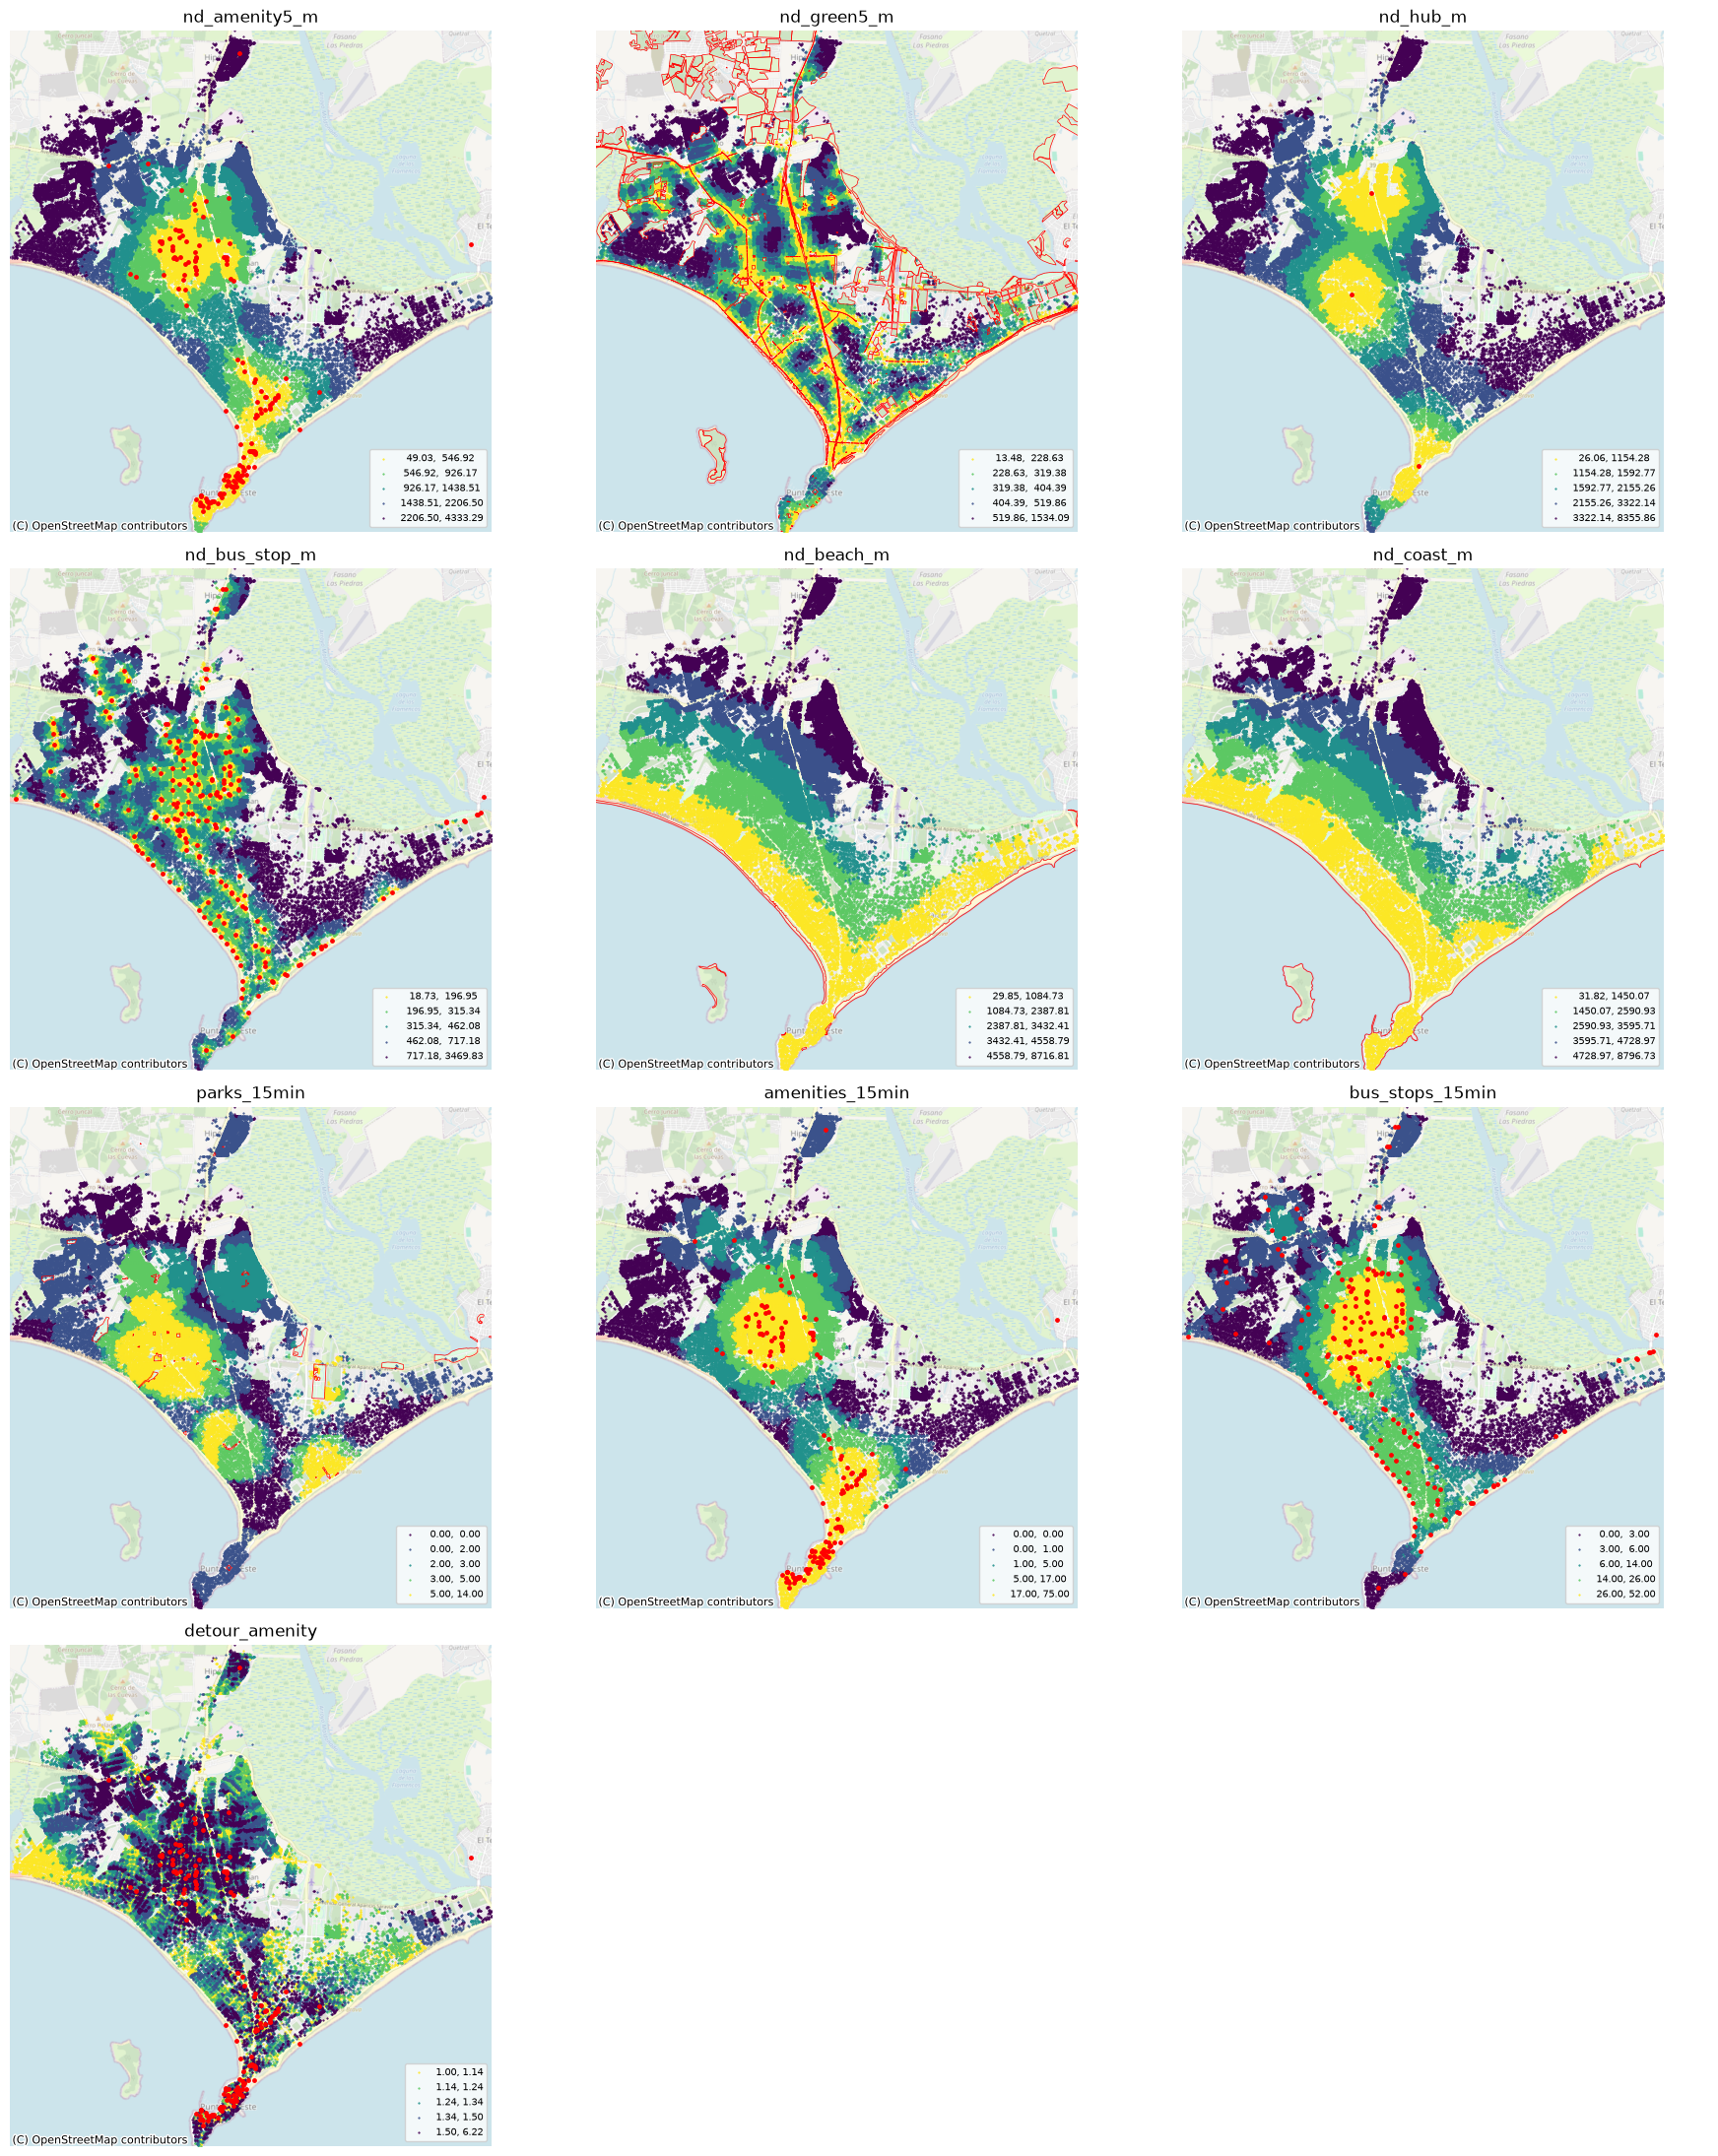

In [ ]:
# OSM tile servers block the default client User-Agent
cx.tile.USER_AGENT = "livability-score-notebook/1.0"
# Web Mercator so the OSM basemap needs no reprojection
pts = bld.set_geometry(cent).to_crs(3857)
maps = [("nd_amenity5_m", amenities), ("nd_green5_m", green), ("nd_hub_m", hubs), ("nd_bus_stop_m", stops),
        ("nd_beach_m", beaches), ("nd_coast_m", coastline), ("parks_15min", parks), ("amenities_15min", amenities),
        ("bus_stops_15min", stops), ("detour_amenity", amenities)]
point_layers = [amenities, hubs, stops]

fig, axes = plt.subplots(4, 3, figsize=(18, 22))
for ax, (col, src) in zip(axes.flat, maps):
    cmap = "viridis_r" if col in dist_cols else "viridis"
    pts.plot(column=col, ax=ax, markersize=0.3, cmap=cmap, scheme="quantiles", k=5,
             legend=True, legend_kwds={"loc": "lower right", "fontsize": 7})
    if any(src is p for p in point_layers):
        src.centroid.to_crs(3857).plot(ax=ax, color="red", markersize=6)
    else:
        g = src.to_crs(3857).geometry
        g.where(~g.geom_type.str.contains("Polygon"), g.boundary).plot(ax=ax, color="red", linewidth=0.5)
    ax.set_xlim(*pts.total_bounds[[0, 2]]); ax.set_ylim(*pts.total_bounds[[1, 3]])
    cx.add_basemap(ax, source=cx.providers.OpenStreetMap.Mapnik, alpha=0.6)
    ax.set_title(col); ax.set_axis_off()
for ax in axes.flat[len(maps):]:
    ax.set_axis_off()
plt.tight_layout()

plt.savefig("output/score_maps.png", dpi=150, bbox_inches="tight")

## Example isochrones
15-minute walking isochrone (street nodes reachable within 1200 m, concave hull) versus the 1200 m circular buffer, for three sample buildings
with low, medium and high amenity access. Amenities reached by the network are shown in red, the rest in grey.

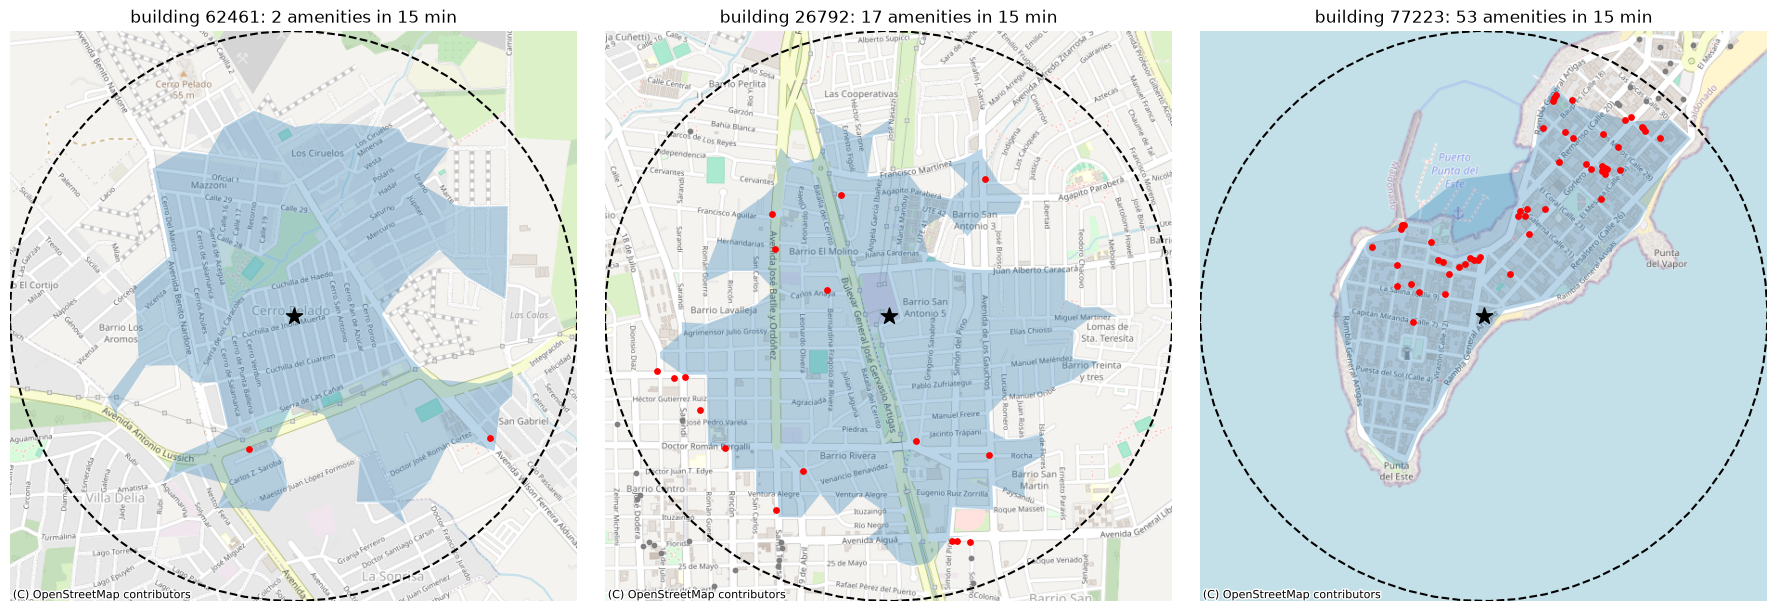

In [11]:
A0 = csr_array((E["w"], (E["i"], E["j"])), shape=(N, N))
order = bld["amenities_15min"].sort_values(kind="stable").index
samples = [order[int(q * (len(order) - 1))] for q in (0.5, 0.8, 0.99)]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, b in zip(axes, samples):
    i = bld.index.get_loc(b)
    d = dijkstra(A0, indices=bnode[i], limit=WALK)
    iso = gpd.GeoSeries([gnodes.geometry[d <= WALK - bsnap[i]].union_all()], crs=CRS).concave_hull(0.2)
    circle = gpd.GeoSeries([cent.iloc[i].buffer(WALK)], crs=CRS)
    reached = D_am[:, bnode[i]] <= WALK - bsnap[i]
    circle.to_crs(3857).boundary.plot(ax=ax, color="black", linestyle="--", label="1200 m buffer")
    iso.to_crs(3857).plot(ax=ax, color="tab:blue", alpha=0.3)
    amenities[~reached].centroid.to_crs(3857).plot(ax=ax, color="grey", markersize=10)
    amenities[reached].centroid.to_crs(3857).plot(ax=ax, color="red", markersize=15)
    gpd.GeoSeries([cent.iloc[i]], crs=CRS).to_crs(3857).plot(ax=ax, color="black", marker="*", markersize=150)
    ax.set_xlim(*circle.to_crs(3857).total_bounds[[0, 2]]); ax.set_ylim(*circle.to_crs(3857).total_bounds[[1, 3]])
    cx.add_basemap(ax, source=cx.providers.OpenStreetMap.Mapnik, alpha=0.7)
    ax.set_title(f"building {b}: {bld.at[b, 'amenities_15min']} amenities in 15 min"); ax.set_axis_off()
plt.tight_layout()

## Livability index
Two-level weighting: normalised variables are averaged within each dimension, then dimensions are combined with fixed weights.
This avoids redundant variables (e.g. beach + coastline, distance + count of the same feature) inflating a theme, and caps the
coast dimension at 15% so the index is not a proxy of distance to the beach. Scaled 0-100.

In [12]:
dims = {"services": (["nd_amenity5_m", "amenities_15min", "detour_amenity"], 0.35),
        "transport": (["nd_bus_stop_m", "bus_stops_15min", "nd_hub_m"], 0.25),
        "green": (["nd_green5_m", "parks_15min"], 0.25),
        "coast": (["nd_beach_m", "nd_coast_m"], 0.15)}

scores = pd.DataFrame({d: bld[[f"n_{c}" for c in cols]].mean(1) for d, (cols, _) in dims.items()})
bld["livability"] = (sum(scores[d] * w for d, (_, w) in dims.items()) * 100).round(1)

print(bld["livability"].describe().round(1).to_dict())
print("Spearman with livability:", scores.corrwith(bld["livability"], method="spearman").round(2).to_dict())

bld.to_crs(4326).to_file("output/buildings_network.gpkg", layer="buildings", driver="GPKG")

C:\Users\guillermo\AppData\Local\Temp\ipykernel_20316\1870485137.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  scores = pd.DataFrame({d: bld[[f"n_{c}" for c in cols]].mean(1) for d, (cols, _) in dims.items()})
C:\Users\guillermo\AppData\Local\Temp\ipykernel_20316\1870485137.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  scores = pd.DataFrame({d: bld[[f"n_{c}" for c in cols]].mean(1) for d, (cols, _) in dims.items()})
C:\Users\guillermo\AppData\Local\Temp\ipykernel_20316\1870485137.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  scores = pd.DataFrame({d: bld[[f"n_{c}" for c in cols]].mean(1) for d, (cols, _) in dims.items()})
C:\Users\guillermo\AppData\Local\Temp\ipykernel_20316\1870485137.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  scores = pd.DataFrame({d: bld[[f"n_{c}"

{'count': 78359.0, 'mean': 46.4, 'std': 16.7, 'min': 4.6, '25%': 32.6, '50%': 44.8, '75%': 59.6, 'max': 89.3}
Spearman with livability: {'services': 0.87, 'transport': 0.82, 'green': 0.74, 'coast': 0.53}
